In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ACER\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ACER\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [5]:
df = pd.read_csv("../dataset/master.csv")
df.head()

,Unnamed: 0,name,category,review,rating,target
0,18110,Headset Gaming Sades T-Power Gaming Headset / ...,elektronik,Kualitas ok\nPelayanan ok,5,Positive
1,32264,Durable Cairan Tikus Mobil Rat Repellent Rumah...,pertukangan,"kemasan bagus,pengiriman dan respon oke semoga...",5,Positive
2,36952,Lem Karet Bat Pingpong Butterfly Free Chack II,olahraga,Ok paket sampaii tks gan,5,Positive
3,24201,[SONIC GEAR] NEW TITAN 5 BTMI Multimedia Speak...,elektronik,"Produk sangat bagus, seller top banget",5,Positive
4,34268,DHS 2002 Bet Bat pingpong / tenis meja,olahraga,.................................................,5,Positive


In [6]:
# 10 data pertama
df.head(10)

,Unnamed: 0,name,category,review,rating,target
0,18110,Headset Gaming Sades T-Power Gaming Headset / ...,elektronik,Kualitas ok\nPelayanan ok,5,Positive
1,32264,Durable Cairan Tikus Mobil Rat Repellent Rumah...,pertukangan,"kemasan bagus,pengiriman dan respon oke semoga...",5,Positive
2,36952,Lem Karet Bat Pingpong Butterfly Free Chack II,olahraga,Ok paket sampaii tks gan,5,Positive
3,24201,[SONIC GEAR] NEW TITAN 5 BTMI Multimedia Speak...,elektronik,"Produk sangat bagus, seller top banget",5,Positive
4,34268,DHS 2002 Bet Bat pingpong / tenis meja,olahraga,.................................................,5,Positive
5,39363,Roda Gerobak Pasir Original Ban angin Kenmaster.,pertukangan,"kualitas barang jelek, lubang baud jebol tidak...",2,Negative
6,109008,[PAYDAY GLOW] WARDAH Gel Moisturizer Series 30...,kecantikan,"Ini emang gada dus nya atau gmna ya,\nPackagin...",3,Neutral
7,7770,Ayam Ceker - 500 gr,makanan_minuman,"cekernya bersih², bungkus nya rapi 👍👍👍",5,Positive
8,50007,Sarung Tangan Billiard Hand Gloves Biliar,olahraga,mantap mantap mantap mantap mantap mantap,5,Positive
9,31948,Rompi Safety Vest Proyek – Hi-Vis Reflektif + ...,pertukangan,"Bagus Banget, Saya akan beli lagi satu lagi",5,Positive


In [7]:
# 10 data terakhir
df.tail(10)

,Unnamed: 0,name,category,review,rating,target
69965,12482,SABERTOOTH Sandal Gunung Traventure Spectra Th...,fashion,Good job. Recommended seller. Thx,5,Positive
69966,12821,KAOS POLOS ANAK LENGAN PANJANG COTTON COMBED 3...,fashion,size 13thn ternyata kecil ya,2,Negative
69967,3914,I Want To Die But I Want To Eat Tteokpokki,hiburan,"sorry cuma kasih bintang 3, sebetulnya mau bin...",3,Neutral
69968,39124,Target Pukul Double For Taekwondo Karate,olahraga,"Sesuai pesanan, barang cepat sampai, respon pe...",5,Positive
69969,11733,Sepatu Wanita Sneakers North Star Neira - 5899...,fashion,Model bagus dan sepatu enak dipakainya.,4,Positive
69970,6680,Hungry Alana - Minced Chicken Misoa with Winte...,makanan_minuman,harta karun para buibu yg selalu dinanti.. men...,5,Positive
69971,3677,Komik One Piece 103 (Eiichiro Oda) Manga Anime,hiburan,Kualitas produk sangat baik. Produk original. ...,5,Positive
69972,38145,Deker / Dekker Lutut / Knee Support LP 758 Ope...,olahraga,ok sesuai pesanan.....,5,Positive
69973,16138,Jam Tangan Wanita Fashion Stainless Steel Stra...,fashion,Kerennn. ......Bos kuu,5,Positive
69974,50252,SFIDN FITS Resistance Band Yoga / Olahraga / S...,olahraga,kualitas barang sangat bagus sesuai dengan des...,5,Positive


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 69975 entries, 0 to 69974
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  69975 non-null  int64
 1   name        69975 non-null  str  
 2   category    69975 non-null  str  
 3   review      69975 non-null  str  
 4   rating      69975 non-null  int64
 5   target      69975 non-null  str  
dtypes: int64(2), str(4)
memory usage: 3.2 MB


In [9]:
df.shape

(69975, 6)

In [10]:
jumlah_dokumen = len(df)
print("Jumlah dokumen:", jumlah_dokumen)

Jumlah dokumen: 69975


In [11]:
text_column = "review"
texts = df[text_column]

for text in texts.head(10):
    print(text)
    print("-" * 80)

Kualitas ok
Pelayanan ok
--------------------------------------------------------------------------------
kemasan bagus,pengiriman dan respon oke semoga hasilnya mantap
--------------------------------------------------------------------------------
Ok paket sampaii tks gan
--------------------------------------------------------------------------------
Produk sangat bagus, seller top banget
--------------------------------------------------------------------------------
..........................................................................................
--------------------------------------------------------------------------------
kualitas barang jelek, lubang baud jebol tidak kuat menahan udara posisi ban di isi angin standart padahal.
--------------------------------------------------------------------------------
Ini emang gada dus nya atau gmna ya,
Packaging sih pake kardus dan bubble wrap,tp dlm nya langsung kemasan ga da dusnya
-------------------------------------------

In [12]:
df.isnull().sum()

Unnamed: 0    0
name          0
category      0
review        0
rating        0
target        0
dtype: int64

In [13]:
df[text_column].isnull().sum()

np.int64(0)

In [14]:
df = df.dropna(subset=[text_column])
df[text_column].isnull().sum()

np.int64(0)

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df[text_column].duplicated().sum()

np.int64(5016)

In [18]:
df = df.drop_duplicates(subset=[text_column])

In [19]:
df[text_column].duplicated().sum()

np.int64(0)

In [20]:
df["jumlah_karakter"] = df[text_column].astype(str).apply(len)
df[[text_column, "jumlah_karakter"]].head()

,review,jumlah_karakter
0,Kualitas ok\nPelayanan ok,24
1,"kemasan bagus,pengiriman dan respon oke semoga...",62
2,Ok paket sampaii tks gan,24
3,"Produk sangat bagus, seller top banget",38
4,.................................................,90


In [21]:
df["jumlah_kata"] = df[text_column].astype(str).apply(
    lambda x: len(x.split())
)
df[[text_column, "jumlah_kata"]].head()

,review,jumlah_kata
0,Kualitas ok\nPelayanan ok,4
1,"kemasan bagus,pengiriman dan respon oke semoga...",8
2,Ok paket sampaii tks gan,5
3,"Produk sangat bagus, seller top banget",6
4,.................................................,1


In [22]:
df["jumlah_kata"].describe()

count    64959.000000
mean        11.374759
std         12.483171
min          1.000000
25%          5.000000
50%          8.000000
75%         14.000000
max       1036.000000
Name: jumlah_kata, dtype: float64

In [24]:
import pandas as pd
import nltk
from nltk.tokenize import sent_tokenize

nltk.download("punkt")
nltk.download("punkt_tab")

df = pd.read_csv("../dataset/master.csv")
text_column = "review"

df["jumlah_kalimat"] = (
    df[text_column]
    .fillna("")
    .astype(str)
    .apply(lambda teks: len(sent_tokenize(teks)))
)

df[[text_column, "jumlah_kalimat"]].head()

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ACER\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ACER\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,review,jumlah_kalimat
0,Kualitas ok\nPelayanan ok,1
1,"kemasan bagus,pengiriman dan respon oke semoga...",1
2,Ok paket sampaii tks gan,1
3,"Produk sangat bagus, seller top banget",1
4,.................................................,1


In [6]:
import pandas as pd
from nltk.tokenize import sent_tokenize

df = pd.read_csv(r"C:\wamp64\www\NLP\Modul-1\dataset\master.csv")
df["jumlah_kalimat"] = df["review"].fillna("").astype(str).apply(
    lambda teks: len(sent_tokenize(teks))
)

df[["review", "jumlah_kalimat"]].head()

,review,jumlah_kalimat
0,Kualitas ok\nPelayanan ok,1
1,"kemasan bagus,pengiriman dan respon oke semoga...",1
2,Ok paket sampaii tks gan,1
3,"Produk sangat bagus, seller top banget",1
4,.................................................,1


In [12]:
print("Jumlah dokumen :", len(df))
print("Jumlah kata    :", df["jumlah_kata"].sum())
print("Jumlah kalimat :", df["jumlah_kalimat"].sum())
print("Jumlah karakter:", df["jumlah_karakter"].sum())

Jumlah dokumen : 69975
Jumlah kata    : 770034
Jumlah kalimat : 120913
Jumlah karakter: 5055282


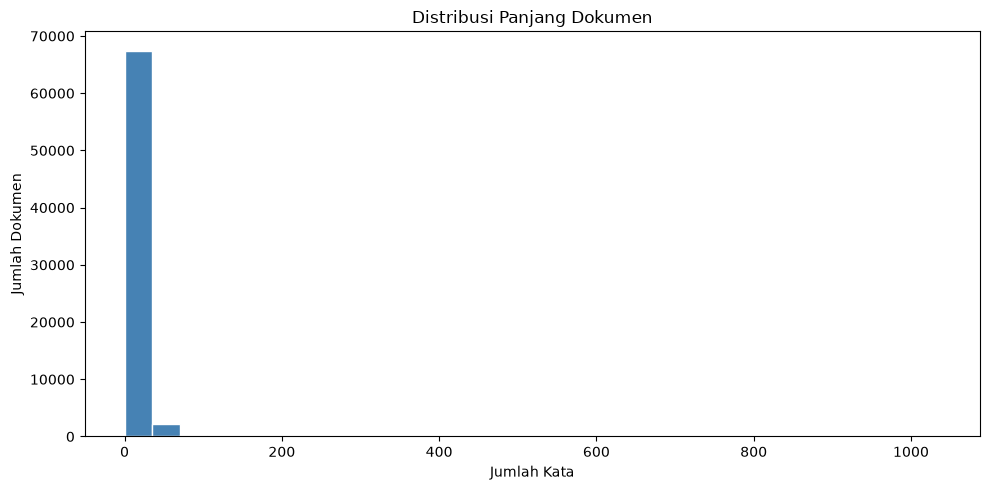

In [13]:
plt.figure(figsize=(10, 5))
plt.hist(df["jumlah_kata"], bins=30, color="steelblue", edgecolor="white")
plt.xlabel("Jumlah Kata")
plt.ylabel("Jumlah Dokumen")
plt.title("Distribusi Panjang Dokumen")
plt.tight_layout()
plt.show()

target
Positive    53140
Negative     8689
Neutral      8146
Name: count, dtype: int64

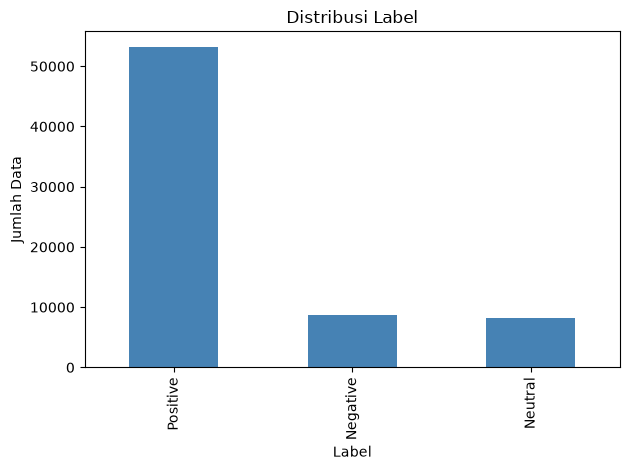

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

dataset_path = Path("..") / "dataset" / "master.csv"
if not dataset_path.exists():
    dataset_path = Path("Modul-1") / "dataset" / "master.csv"

df = pd.read_csv(dataset_path)
label_column = "target"
label_counts = df[label_column].value_counts()

display(label_counts)
label_counts.plot(kind="bar", color="steelblue")
plt.xlabel("Label")
plt.ylabel("Jumlah Data")
plt.title("Distribusi Label")
plt.tight_layout()
plt.show()